**Task: 3**• Do a labelling of about 150 images through labelling tools and
develop your own model train and test on the data and show
the results

## Step 0: Imports

In [1]:
import os, glob, random, time
import xml.etree.ElementTree as ET
import numpy as np, cv2
import matplotlib.pyplot as plt, matplotlib.patches as patches
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

random.seed(0); np.random.seed(0); torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## Step 1: Data

- **Demo (default):** random squares, circles, triangles (150 train / 50 val images).
- **Your own data:** label ~150 images with [labelImg](https://github.com/HumanSignal/labelImg) (export **Pascal VOC XML**), put images + `.xml` files in one folder, upload it to Colab, and set `ZIP_PATH` (or leave it `None` to auto-detect a .zip in `/content`).

In [4]:

USE_CUSTOM_DATA = True
ZIP_PATH = "/content/150 data set.v1i.voc.zip"


DATA_DIR = None
if USE_CUSTOM_DATA:
    import zipfile
    if ZIP_PATH is None:
        zips = glob.glob("/content/*.zip")
        ZIP_PATH = zips[0] if zips else None
    if ZIP_PATH is None or not os.path.exists(ZIP_PATH):
        raise FileNotFoundError("No zip found. Upload your zip to /content (Files panel on the left) and set ZIP_PATH.")
    print("Using zip:", ZIP_PATH)
    try:
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall("/content/my_data")
    except zipfile.BadZipFile:
        print("\n" + "!" * 60)
        print("ERROR: The file is not recognized as a valid zip file.")
        print("Please verify:")
        print("1. The upload is fully complete (wait for the circle indicator on the bottom-left to finish).")
        print("2. The file is actually a valid ZIP archive on your local computer.")
        print("3. You can set USE_CUSTOM_DATA = False if you want to use the demo data instead.")
        print("!" * 60 + "\n")
        raise

    xmls = glob.glob("/content/my_data/**/*.xml", recursive=True)
    print("xml files found:", len(xmls))
    if not xmls:
        print("Top-level contents:", os.listdir("/content/my_data")[:20])
        print("txt:", len(glob.glob("/content/my_data/**/*.txt", recursive=True)),
              "| json:", len(glob.glob("/content/my_data/**/*.json", recursive=True)))
        raise RuntimeError("No .xml files in the zip. Export your labels as Pascal VOC (XML) and zip again.")
    DATA_DIR = "/content/my_data"      # all subfolders are searched automatically
    print("DATA_DIR =", DATA_DIR)

Using zip: /content/150 data set.v1i.voc.zip
xml files found: 234
DATA_DIR = /content/my_data


train 184 | val 45 | classes ['Book', 'Bottle', 'Plate']


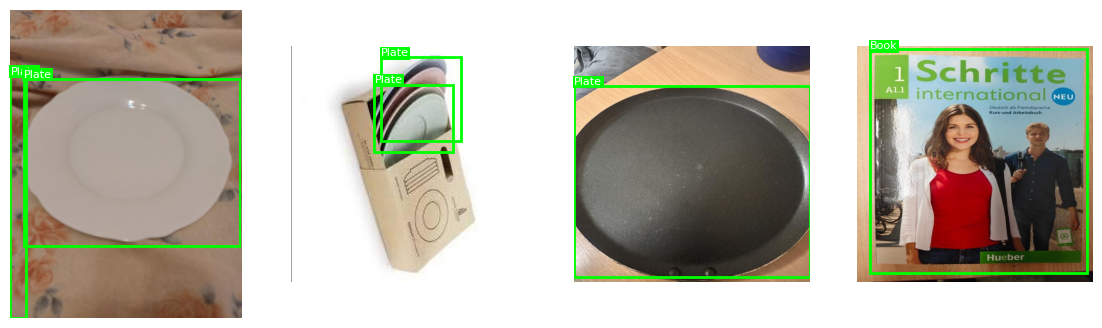

In [5]:

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

# demo dataset
def make_sample(rng, size=256):
    img = np.clip(rng.integers(200, 256, (1,1,3)) + rng.normal(0, 6, (size,size,3)), 0, 255).astype(np.uint8).copy()
    boxes, labels = [], []
    for _ in range(int(rng.integers(1, 5))):
        s = int(rng.integers(32, 90)); x, y = int(rng.integers(0, size-s)), int(rng.integers(0, size-s))
        box = [x, y, x+s, y+s]
        if any(iou(box, b) > 0.05 for b in boxes): continue
        lab = int(rng.integers(1, 4)); col = tuple(int(v) for v in rng.integers(0, 160, 3))
        if lab == 1:   cv2.rectangle(img, (x, y), (x+s, y+s), col, -1)
        elif lab == 2: cv2.circle(img, (x+s//2, y+s//2), s//2, col, -1)
        else:          cv2.fillPoly(img, [np.array([[x+s//2, y], [x, y+s], [x+s, y+s]], np.int32)], col)
        boxes.append(box); labels.append(lab)
    return img, np.array(boxes, np.float32), np.array(labels, np.int64)

class ShapesDataset(Dataset):
    def __init__(self, n, seed):
        rng = np.random.default_rng(seed); self.data = [make_sample(rng) for _ in range(n)]
    def __len__(self): return len(self.data)
    def __getitem__(self, i):
        img, b, l = self.data[i]
        return torch.from_numpy(img).permute(2,0,1).float()/255, {"boxes": torch.from_numpy(b), "labels": torch.from_numpy(l)}

#  your own data (Pascal VOC XML)
def load_voc(root):
    samples, names = [], set()
    for xp in sorted(glob.glob(os.path.join(root, "**", "*.xml"), recursive=True)):
        r = ET.parse(xp).getroot(); folder = os.path.dirname(xp)
        path = os.path.join(folder, r.findtext("filename"))
        if not os.path.exists(path):
            stem = os.path.splitext(os.path.basename(xp))[0]
            found = [p for p in glob.glob(os.path.join(folder, stem + ".*")) if not p.endswith(".xml")]
            if not found: print('image not found for', xp); continue
            path = found[0]
        boxes, labs = [], []
        for o in r.findall("object"):
            bb = o.find("bndbox"); b = [float(bb.findtext(k)) for k in ("xmin","ymin","xmax","ymax")]
            if b[2] > b[0] and b[3] > b[1]: boxes.append(b); labs.append(o.findtext("name").strip())
        if boxes: samples.append((path, np.array(boxes, np.float32), labs)); names.update(labs)
    return samples, sorted(names)

class VOCDataset(Dataset):
    def __init__(self, samples, classes): self.s, self.c = samples, {n: i+1 for i, n in enumerate(classes)}
    def __len__(self): return len(self.s)
    def __getitem__(self, i):
        p, b, l = self.s[i]; img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        return torch.from_numpy(img).permute(2,0,1).float()/255, {"boxes": torch.from_numpy(b), "labels": torch.tensor([self.c[n] for n in l])}

# build train / val
if USE_CUSTOM_DATA:
    samples, CLASS_NAMES = load_voc(DATA_DIR); random.shuffle(samples)
    if len(samples) < 2:
        raise RuntimeError(f"Only {len(samples)} usable labelled images found. Each .xml needs a matching image "
                           "(same name, e.g. img1.jpg + img1.xml) and at least one box.")
    nv = max(1, len(samples)//5)
    train_ds, val_ds = VOCDataset(samples[nv:], CLASS_NAMES), VOCDataset(samples[:nv], CLASS_NAMES)
    MIN_SIZE, MAX_SIZE, ANCHORS = 480, 640, (32, 64, 128, 256)   # change anchors to match your object sizes
else:
    CLASS_NAMES = ["square", "circle", "triangle"]
    train_ds, val_ds = ShapesDataset(150, 1), ShapesDataset(50, 2)
    MIN_SIZE, MAX_SIZE, ANCHORS = 256, 256, (32, 64, 128)

NUM_CLASSES = len(CLASS_NAMES) + 1          # + background
collate = lambda b: tuple(zip(*b))
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_ds,   batch_size=8, shuffle=False, collate_fn=collate)
print(f"train {len(train_ds)} | val {len(val_ds)} | classes {CLASS_NAMES}")

# drawing helper
def draw(ax, img, boxes, labels, scores=None, color=None, title=""):
    ax.imshow(img.permute(1,2,0).numpy())
    for i, (b, l) in enumerate(zip(boxes, labels)):
        c = color or "red"
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor=c, linewidth=2))
        t = CLASS_NAMES[int(l)-1] + (f" {float(scores[i]):.2f}" if scores is not None else "")
        ax.text(b[0], max(b[1]-3, 8), t, color="white", fontsize=8, bbox=dict(facecolor=c, pad=1, edgecolor="none"))
    ax.set_title(title); ax.axis("off")

fig, axs = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(axs, random.sample(range(len(train_ds)), 4)):
    im, t = train_ds[i]; draw(ax, im, t["boxes"], t["labels"], color="lime")
plt.show()

## Step 2: Model



In [6]:
class Backbone(nn.Module):
    def __init__(self, channels=(64, 128, 256, 512)):
        super().__init__()
        layers, prev = [], 3
        for i, c in enumerate(channels):
            layers += [nn.Conv2d(prev, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(True)]
            if i < len(channels) - 1: layers.append(nn.MaxPool2d(2))
            prev = c
        self.body = nn.Sequential(*layers); self.out_channels = prev
    def forward(self, x): return self.body(x)

def build_model(channels=(64, 128, 256, 512)):
    return FasterRCNN(
        Backbone(channels), num_classes=NUM_CLASSES,
        rpn_anchor_generator=AnchorGenerator(sizes=(ANCHORS,), aspect_ratios=((0.5, 1.0, 2.0),)),
        box_roi_pool=MultiScaleRoIAlign(["0"], output_size=7, sampling_ratio=2),
        min_size=MIN_SIZE, max_size=MAX_SIZE, box_score_thresh=0.05).to(device)

model = build_model()
print("parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

parameters: 30,704,720


## Step 3: Train + evaluate (IoU → precision/recall → mAP)



In [7]:
def calc_map(preds, gts, num_classes, thr=0.5):
    aps = {}
    for c in range(1, num_classes):
        dets, gtb, n_gt = [], [], 0
        for i, (p, g) in enumerate(zip(preds, gts)):
            gtb.append(g["boxes"][g["labels"] == c]); n_gt += len(gtb[-1])
            for b, s in zip(p["boxes"][p["labels"] == c], p["scores"][p["labels"] == c]): dets.append((s, i, b))
        if n_gt == 0: continue
        dets.sort(key=lambda d: -d[0]); used = [np.zeros(len(g), bool) for g in gtb]; tp = np.zeros(len(dets))
        for k, (s, i, b) in enumerate(dets):
            if len(gtb[i]):
                ious = [iou(b, g) for g in gtb[i]]; j = int(np.argmax(ious))
                if ious[j] >= thr and not used[i][j]: tp[k] = 1; used[i][j] = True
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
        rec, prec = ctp / n_gt, ctp / np.maximum(ctp + cfp, 1e-9)
        mrec, mpre = np.r_[0, rec, 1], np.r_[0, prec, 0]
        for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i+1])
        idx = np.where(mrec[1:] != mrec[:-1])[0]
        aps[c] = float(np.sum((mrec[idx+1] - mrec[idx]) * mpre[idx+1]))
    return (float(np.mean(list(aps.values()))) if aps else 0.0), aps

@torch.no_grad()
def predict(model, loader):
    model.eval(); preds, gts = [], []
    for imgs, tg in loader:
        for o, t in zip(model([i.to(device) for i in imgs]), tg):
            preds.append({k: v.cpu().numpy() for k, v in o.items()})
            gts.append({k: v.numpy() for k, v in t.items()})
    return preds, gts

def train(model, epochs=30, lr=1e-3, eval_every=5):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    losses, maps = [], []
    for ep in range(1, epochs + 1):
        model.train(); total = 0
        for imgs, tg in train_loader:
            loss = sum(model([i.to(device) for i in imgs], [{k: v.to(device) for k, v in t.items()} for t in tg]).values())
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 10); opt.step(); total += loss.item()
        sched.step(); losses.append(total / len(train_loader)); msg = f"epoch {ep}/{epochs}  loss {losses[-1]:.3f}"
        if ep % eval_every == 0 or ep == epochs:
            m, _ = calc_map(*predict(model, val_loader), NUM_CLASSES); maps.append((ep, m)); msg += f"  val mAP@0.5 {m:.3f}"
        print(msg)
    return losses, maps

losses, maps = train(model, epochs=30)

epoch 1/30  loss 7.728
epoch 2/30  loss 2.055
epoch 3/30  loss 1.842
epoch 4/30  loss 1.838
epoch 5/30  loss 1.846  val mAP@0.5 0.051
epoch 6/30  loss 1.769
epoch 7/30  loss 1.776
epoch 8/30  loss 1.797
epoch 9/30  loss 1.685
epoch 10/30  loss 1.720  val mAP@0.5 0.077
epoch 11/30  loss 1.632
epoch 12/30  loss 1.656
epoch 13/30  loss 1.628
epoch 14/30  loss 1.609
epoch 15/30  loss 1.517  val mAP@0.5 0.123
epoch 16/30  loss 1.506
epoch 17/30  loss 1.497
epoch 18/30  loss 1.456
epoch 19/30  loss 1.356
epoch 20/30  loss 1.382  val mAP@0.5 0.179
epoch 21/30  loss 1.302
epoch 22/30  loss 1.339
epoch 23/30  loss 1.278
epoch 24/30  loss 1.262
epoch 25/30  loss 1.250  val mAP@0.5 0.202
epoch 26/30  loss 1.230
epoch 27/30  loss 1.211
epoch 28/30  loss 1.191
epoch 29/30  loss 1.183
epoch 30/30  loss 1.182  val mAP@0.5 0.211


### Results:

mAP@0.5 = 0.211
  AP       Book: 0.182
  AP     Bottle: 0.214
  AP      Plate: 0.238


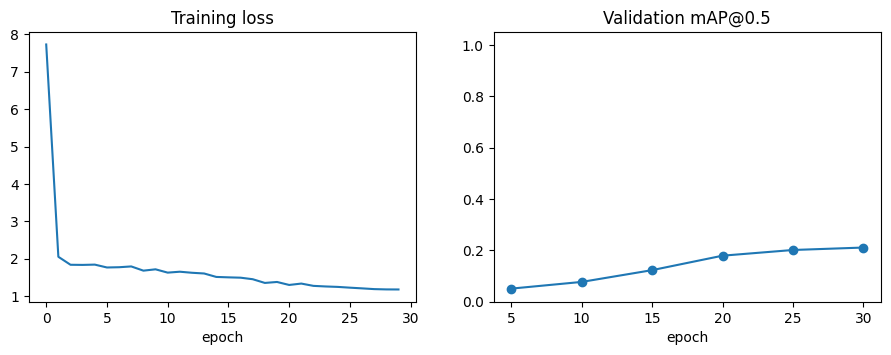

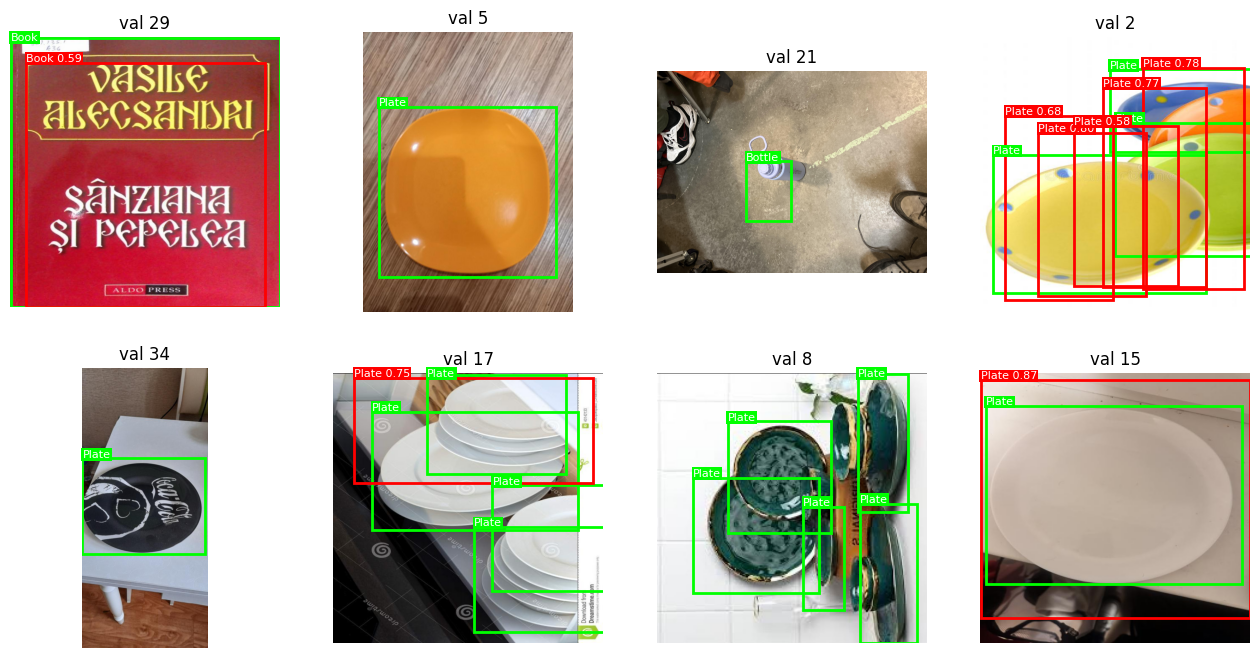

In [8]:
preds, gts = predict(model, val_loader)
mAP, per_class = calc_map(preds, gts, NUM_CLASSES)
print(f"mAP@0.5 = {mAP:.3f}")
for c, ap in per_class.items(): print(f"  AP {CLASS_NAMES[c-1]:>10}: {ap:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(*zip(*maps), marker="o"); ax[1].set_title("Validation mAP@0.5"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1.05)
plt.show()

fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axs.ravel(), random.sample(range(len(val_ds)), min(8, len(val_ds)))):
    im, t = val_ds[i]; keep = preds[i]["scores"] >= 0.5
    draw(ax, im, t["boxes"], t["labels"], color="lime")
    draw(ax, im, preds[i]["boxes"][keep], preds[i]["labels"][keep], preds[i]["scores"][keep], title=f"val {i}")
plt.show()

## Task 3:• Do a labelling of about 150 images through labelling tools and
develop your own model train and test on the data and show
the results



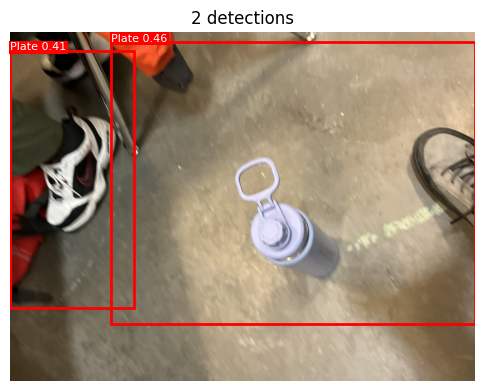

In [12]:
def test_image(path, thr=0.5):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    t = torch.from_numpy(img).permute(2,0,1).float() / 255
    model.eval()
    with torch.no_grad(): o = model([t.to(device)])[0]
    k = (o["scores"] >= thr).cpu()
    fig, ax = plt.subplots(figsize=(6, 6))
    draw(ax, t, o["boxes"].cpu()[k], o["labels"].cpu()[k], o["scores"].cpu()[k], title=f"{k.sum().item()} detections")
    plt.show()


im, _ = val_ds[random.randrange(len(val_ds))]
cv2.imwrite("random_test.png", cv2.cvtColor((im.permute(1,2,0).numpy()*255).astype(np.uint8), cv2.COLOR_RGB2BGR))
test_image("random_test.png", thr=0.3)